In [24]:
import pandas as pd
df = pd.read_csv("03_polynomial_machine_temperature.csv")
df.head()

,Operating_Hours,Machine_Temperature_C
0,10.37,134.13
1,1.00,45.70
2,1.19,48.30
3,7.63,108.69
4,5.01,74.54


In [25]:
x = df[['Operating_Hours']]
y = df['Machine_Temperature_C']

In [26]:
from sklearn.preprocessing import PolynomialFeatures

poly2 = PolynomialFeatures(degree=2)
x_poly2 = poly2.fit_transform(x)

poly3 = PolynomialFeatures(degree=3)
x_poly3 = poly3.fit_transform(x)

In [27]:
from sklearn.model_selection import train_test_split
X_train2, X_test2, Y_train2, Y_test2 = train_test_split(x_poly2,y,train_size=0.8,random_state=42)
X_train3, X_test3, Y_train3, Y_test3 = train_test_split(x_poly3,y,train_size=0.8,random_state=42)


In [28]:
from sklearn.linear_model import LinearRegression

model2 = LinearRegression().fit(X_train2, Y_train2)
model3 = LinearRegression().fit(X_train3, Y_train3)

In [29]:
from sklearn.metrics import r2_score

y_pred2 = model2.predict(X_test2)
y_pred3 = model3.predict(X_test3)

score2 = r2_score(Y_test2, y_pred2)
score3 = r2_score(Y_test3, y_pred3)

print(f"Degree 2 R² Score: {score2 * 100:.2f}%")
print(f"Degree 3 R² Score: {score3 * 100:.2f}%")

Degree 2 R² Score: 97.94%
Degree 3 R² Score: 97.93%


In [ ]:
#Degree 2:

hours = float(input("\nEnter Operating Hours: "))
hours_poly2 = poly2.transform([[hours]])
pred_temp = model2.predict(hours_poly2)
print(f"Predicted Temperature (Degree 2): {pred_temp[0]:.2f} °C")

Predicted Temperature (Degree 2): 470.70 °C


c:\Users\<user>\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


In [ ]:
#Degree 3:

hours = float(input("\nEnter Operating Hours: "))
hours_poly3 = poly3.transform([[hours]])
pred_temp = model3.predict(hours_poly3)
print(f"Predicted Temperature (Degree 3): {pred_temp[0]:.2f} °C")

Predicted Temperature (Degree 3): 359.73 °C


c:\Users\<user>\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


c:\Users\<user>\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(
c:\Users\<user>\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


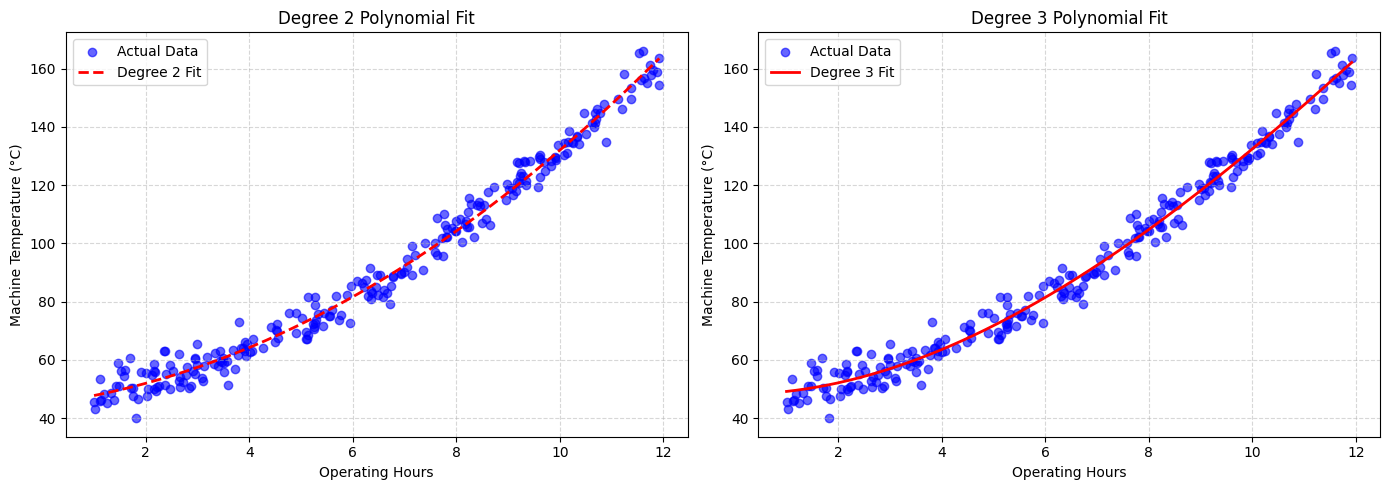

In [37]:
import matplotlib.pyplot as plt
import numpy as np

# Sequence for line generation
X_seq = np.linspace(x.min(), x.max(), 300).reshape(-1, 1)

plt.figure(figsize=(14, 5))

# Plot 1: Degree 2
plt.subplot(1, 2, 1)
plt.scatter(x, y, color='blue', alpha=0.6, label='Actual Data')
plt.plot(X_seq, model2.predict(poly2.transform(X_seq)), color='red', linewidth=2, linestyle='--', label='Degree 2 Fit')
plt.xlabel('Operating Hours')
plt.ylabel('Machine Temperature (°C)')
plt.title('Degree 2 Polynomial Fit')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

# Plot 2: Degree 3
plt.subplot(1, 2, 2)
plt.scatter(x, y, color='blue', alpha=0.6, label='Actual Data')
plt.plot(X_seq, model3.predict(poly3.transform(X_seq)), color='red', linewidth=2, label='Degree 3 Fit')
plt.xlabel('Operating Hours')
plt.ylabel('Machine Temperature (°C)')
plt.title('Degree 3 Polynomial Fit')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()